# Topic Modelling with LDA

## Objective

This notebook demonstrates Latent Dirichlet Allocation (LDA) using scikit-learn on a
sample corpus containing anonymised technology resumes, job descriptions and project
briefs. It is a separate NLP-subject exercise: the Flask dashboard uses semantic matching
for ranking, while this notebook shows how unsupervised topics can be discovered from
unlabelled text.

### What this notebook covers

1. A sample corpus of resumes and job descriptions.
2. Preprocessing and stop-word removal.
3. `CountVectorizer` document-term matrix.
4. LDA training, topic keywords and document-topic distributions.
5. Visualisations and an interpretation based on the fitted model.

The corpus is embedded in this notebook so it can be executed independently.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_colwidth", 95)
RANDOM_STATE = 42
N_TOPICS = 4
print("Libraries imported. CountVectorizer and LDA are ready.")

Libraries imported. CountVectorizer and LDA are ready.


## 1. Sample corpus

The corpus mixes three document types. All names and employers are fictional. There are
no topic labels supplied to the model: the themes are discovered purely from word
co-occurrence.

In [2]:
documents = [
  {
    "id": "doc-01",
    "title": "Resume - Data Scientist (Priya S.)",
    "category": "resume",
    "text": "Data scientist with five years of experience in predictive modelling and statistical analysis. Built classification and regression models with Python, pandas, NumPy, scikit-learn and XGBoost. Designed A/B tests, performed feature engineering and evaluated models with cross-validation. Created dashboards in Tableau and Power BI and wrote complex SQL queries against a cloud data warehouse. Experience with Apache Spark, Jupyter notebooks and time series forecasting. Strong statistics background and experience explaining model results to business stakeholders."
  },
  {
    "id": "doc-02",
    "title": "Resume - Machine Learning Engineer (Arjun M.)",
    "category": "resume",
    "text": "Machine learning engineer focused on production model deployment and scalable training pipelines. Trained deep learning models with PyTorch and TensorFlow, served models behind FastAPI microservices and containerised workloads with Docker and Kubernetes. Automated retraining and experiment tracking with MLflow, Airflow and CI/CD. Monitored model drift and latency in production. Strong Python, SQL, pandas and NumPy skills, with experience on AWS and GCP. Built feature stores and real-time inference services for recommendation models."
  },
  {
    "id": "doc-03",
    "title": "Resume - NLP Engineer (Meera I.)",
    "category": "resume",
    "text": "NLP engineer building language understanding systems. Developed named entity recognition, text classification and sentiment analysis pipelines with spaCy, NLTK and Hugging Face transformers. Fine-tuned BERT models, created sentence embeddings and implemented semantic search with vector databases. Built retrieval augmented generation applications with LangChain and large language models. Evaluated model quality with precision, recall and human review. Deployed NLP services with FastAPI and Docker. Experience with topic modelling, tokenisation, lemmatisation and multilingual text processing."
  },
  {
    "id": "doc-04",
    "title": "Resume - Python Backend Developer (Rahul V.)",
    "category": "resume",
    "text": "Backend developer specialising in Python web services and relational databases. Built REST APIs with Flask and Django, designed PostgreSQL schemas and optimised SQL queries. Wrote unit tests with pytest, automated deployments with GitHub Actions and Docker, and maintained services on Linux. Implemented JWT authentication and OAuth integrations. Collaborated with frontend engineers using Git and participated in code reviews. Experience with Redis caching, API design and object oriented programming."
  },
  {
    "id": "doc-05",
    "title": "Resume - Full-Stack Developer (Sneha K.)",
    "category": "resume",
    "text": "Full-stack web developer building responsive applications with JavaScript, TypeScript, React, Next.js, HTML and CSS. Created reusable components with Tailwind CSS and managed application state. Developed REST and GraphQL APIs with Node.js and Express, connected to MongoDB and PostgreSQL. Implemented JWT authentication, wrote unit tests and deployed applications with Docker on AWS. Worked in agile teams using Git, GitHub and CI/CD. Focused on accessibility, performance and clean user interfaces."
  },
  {
    "id": "doc-06",
    "title": "Resume - DevOps Engineer (Vikram R.)",
    "category": "resume",
    "text": "DevOps engineer automating cloud infrastructure and continuous delivery. Provisioned AWS resources with Terraform, managed Kubernetes clusters and containerised services with Docker. Built CI/CD pipelines with Jenkins and GitHub Actions, configured Linux servers and Nginx reverse proxies. Implemented monitoring, logging and alerting for production systems. Automated configuration management and secrets rotation. Strong background in networking, shell scripting, Python automation and site reliability practices."
  },
  {
    "id": "doc-07",
    "title": "Resume - Data Analyst (Ananya P.)",
    "category": "resume",
    "text": "Data analyst turning operational data into business reports and dashboards. Used SQL, Excel, Tableau and Power BI to analyse sales, marketing and customer data. Cleaned datasets with pandas, wrote statistical summaries and visualised trends with matplotlib and seaborn. Ran A/B testing analysis and built KPI reports for product teams. Experience with data quality checks, ETL pipelines and stakeholder communication. Strong attention to detail and clear written reporting."
  },
  {
    "id": "doc-08",
    "title": "Job - Data Scientist",
    "category": "job_description",
    "text": "We are hiring a data scientist to turn complex datasets into actionable insights. You will perform statistical analysis and predictive modelling with Python, pandas, scikit-learn and SQL, design A/B tests and communicate findings with Tableau or Power BI. Experience with feature engineering, time series forecasting, Apache Spark and cloud data platforms is desirable. The role requires strong statistics fundamentals and the ability to explain machine learning results to non-technical stakeholders."
  },
  {
    "id": "doc-09",
    "title": "Job - NLP Engineer",
    "category": "job_description",
    "text": "We are looking for an NLP engineer to build language understanding and text analytics systems. You will develop named entity recognition, text classification, sentiment analysis and semantic search using spaCy, transformers and sentence embeddings. Experience fine-tuning BERT, building retrieval augmented generation pipelines with large language models and evaluating models with rigorous metrics is required. Familiarity with Python, PyTorch, FastAPI, Docker and topic modelling is valued."
  },
  {
    "id": "doc-10",
    "title": "Job - Python Backend Engineer",
    "category": "job_description",
    "text": "Seeking a Python backend engineer to design and maintain REST APIs and database services. You will write clean Python with Flask or Django, model relational data in PostgreSQL or MySQL, write SQL queries and unit tests with pytest, and deploy applications with Docker and CI/CD. Experience with Linux, Redis, JWT authentication, API design and cloud platforms such as AWS is a plus. Strong understanding of data structures, algorithms and object oriented programming is required."
  },
  {
    "id": "doc-11",
    "title": "Job - Full-Stack Developer",
    "category": "job_description",
    "text": "Hiring a full-stack developer to build modern web applications end to end. You will use JavaScript, TypeScript, React and Tailwind CSS on the frontend, and Node.js, Express and GraphQL on the backend, backed by MongoDB or PostgreSQL. Experience with JWT authentication, responsive design, unit testing, Git, Docker and CI/CD is required. Familiarity with AWS deployment, accessibility and agile product development is a plus."
  },
  {
    "id": "doc-12",
    "title": "Job - DevOps / Cloud Engineer",
    "category": "job_description",
    "text": "We need a DevOps engineer to operate reliable cloud infrastructure. You will manage AWS environments with Terraform, run Kubernetes and Docker workloads, and build CI/CD pipelines with Jenkins or GitHub Actions. Responsibilities include Linux administration, Nginx configuration, monitoring, logging, incident response and automation with Python or shell scripting. Experience with site reliability engineering, networking and secure secret management is required."
  },
  {
    "id": "doc-13",
    "title": "Project brief - Customer churn prediction",
    "category": "project_brief",
    "text": "Build a machine learning pipeline that predicts customer churn from historical subscription data. The team will clean data with pandas, engineer behavioural features, train classification models with scikit-learn and XGBoost, and evaluate precision, recall and ROC AUC. Deliverables include an explainable model report, a Tableau dashboard for business users and a batch scoring job running on Apache Spark. SQL access to the data warehouse is provided."
  },
  {
    "id": "doc-14",
    "title": "Project brief - Support ticket triage",
    "category": "project_brief",
    "text": "Create an NLP system that classifies incoming support tickets by topic and urgency. The solution should use text preprocessing, sentence embeddings and a transformer classifier, with named entity recognition for product names and dates. Build a FastAPI service, containerise it with Docker and deploy it to Kubernetes. Add a retrieval augmented generation assistant that answers common questions from the documentation, with evaluation of answer relevance and latency."
  },
  {
    "id": "doc-15",
    "title": "Project brief - Analytics dashboard platform",
    "category": "project_brief",
    "text": "Develop a web analytics dashboard for product and marketing teams. The frontend uses React, TypeScript and Tailwind CSS, while the backend exposes REST APIs built with Node.js and Express over PostgreSQL. Include authentication with JWT, role based access control, responsive charts and exportable reports. Write unit tests, configure CI/CD with GitHub Actions, deploy with Docker on AWS and monitor application performance."
  }
]

corpus_df = pd.DataFrame(documents)
print(f"Documents: {len(corpus_df)}")
display(corpus_df.groupby("category").size().rename("documents").to_frame())
display(corpus_df[["id", "title", "category"]])
print("Example document text:")
print(corpus_df.loc[0, "text"])

Documents: 15


,documents
category,
job_description,5
project_brief,3
resume,7


,id,title,category
0,doc-01,Resume - Data Scientist (Priya S.),resume
1,doc-02,Resume - Machine Learning Engineer (Arjun M.),resume
2,doc-03,Resume - NLP Engineer (Meera I.),resume
3,doc-04,Resume - Python Backend Developer (Rahul V.),resume
4,doc-05,Resume - Full-Stack Developer (Sneha K.),resume
5,doc-06,Resume - DevOps Engineer (Vikram R.),resume
6,doc-07,Resume - Data Analyst (Ananya P.),resume
7,doc-08,Job - Data Scientist,job_description
8,doc-09,Job - NLP Engineer,job_description
9,doc-10,Job - Python Backend Engineer,job_description


Example document text:
Data scientist with five years of experience in predictive modelling and statistical analysis. Built classification and regression models with Python, pandas, NumPy, scikit-learn and XGBoost. Designed A/B tests, performed feature engineering and evaluated models with cross-validation. Created dashboards in Tableau and Power BI and wrote complex SQL queries against a cloud data warehouse. Experience with Apache Spark, Jupyter notebooks and time series forecasting. Strong statistics background and experience explaining model results to business stakeholders.


## 2. Text preprocessing

We lowercase the text, remove punctuation and numerals, drop scikit-learn's English stop
words plus a few domain-neutral filler terms, and keep short tokens that carry technical
meaning (for example `r`, `c` and `ml`). Bigrams are added later by `CountVectorizer` so
phrases such as `machine learning` remain visible.

In [3]:
EXTRA_STOP_WORDS = {
    "experience", "worked", "working", "strong", "ability", "team", "teams",
    "using", "used", "including", "knowledge", "skills", "role", "roles",
    "years", "year", "well", "good", "new", "make", "help", "across",
}
STOP_WORDS = sorted(set(ENGLISH_STOP_WORDS) | EXTRA_STOP_WORDS)
KEEP_TOKENS = {"r", "c", "ml", "ai", "sql", "api", "qa"}

def preprocess(text: str) -> str:
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9+#.]+", " ", text)
    tokens = [
        token.strip(".")
        for token in text.split()
        if token.strip(".") and (token.strip(".") in KEEP_TOKENS or token.strip(".") not in STOP_WORDS)
    ]
    return " ".join(tokens)

corpus_df["processed"] = corpus_df["text"].apply(preprocess)
display(corpus_df[["title", "processed"]].head(5))

,title,processed
0,Resume - Data Scientist (Priya S.),data scientist predictive modelling statistical analysis built classification regression mo...
1,Resume - Machine Learning Engineer (Arjun M.),machine learning engineer focused production model deployment scalable training pipelines t...
2,Resume - NLP Engineer (Meera I.),nlp engineer building language understanding systems developed named entity recognition tex...
3,Resume - Python Backend Developer (Rahul V.),backend developer specialising python web services relational databases built rest apis fla...
4,Resume - Full-Stack Developer (Sneha K.),stack web developer building responsive applications javascript typescript react next.js ht...


## 3. CountVectorizer document-term matrix

`min_df=1` keeps rare technical terms in this small teaching corpus, while `max_df=0.85`
removes terms appearing in almost every document. `ngram_range=(1, 2)` allows single words
and bigrams.

In [4]:
vectorizer = CountVectorizer(
    stop_words=STOP_WORDS,
    ngram_range=(1, 2),
    min_df=1,
    max_df=0.85,
    max_features=800,
)
X = vectorizer.fit_transform(corpus_df["processed"])
terms = vectorizer.get_feature_names_out()

print(f"Document-term matrix: {X.shape[0]} documents x {X.shape[1]} terms")
print(f"Total token occurrences: {int(X.sum())}")
print("Sample terms:", list(terms[:20]))

Document-term matrix: 15 documents x 800 terms
Total token occurrences: 1262
Sample terms: ['access', 'accessibility', 'accessibility performance', 'actionable', 'actionable insights', 'actions', 'actions configured', 'actions deploy', 'actions docker', 'actions responsibilities', 'add', 'add retrieval', 'administration', 'administration nginx', 'agile', 'agile git', 'agile product', 'analysis', 'analysis built', 'analytics']


## 4. LDA model training

We fit four topics with a fixed random seed so the output is reproducible. Perplexity is
printed as a diagnostic; with a corpus this small it is useful for comparison across
settings, not as an absolute quality score.

In [5]:
lda = LatentDirichletAllocation(
    n_components=N_TOPICS,
    learning_method="batch",
    max_iter=30,
    random_state=RANDOM_STATE,
    evaluate_every=-1,
)
doc_topic = lda.fit_transform(X)
print(f"Fitted {N_TOPICS} topics over {X.shape[0]} documents.")
print(f"Model perplexity (lower is better for comparison): {lda.perplexity(X):.2f}")

Fitted 4 topics over 15 documents.


Model perplexity (lower is better for comparison): 1063.19


## 5. Topic extraction and important keywords

Each topic is a distribution over vocabulary terms. The table below lists the eight
highest-weight terms per topic; the bar chart visualises their relative weights inside
each topic component.

,topic,keywords
0,Topic 1,"js, css, docker, product, tailwind css, react, express, node js"
1,Topic 2,"data, python, pipelines, cloud, engineer, linux, cd, aws"
2,Topic 3,"models, services, wrote, built, model, sql, python, docker"
3,Topic 4,"data, models, text, language, analysis, modelling, classification, nlp"


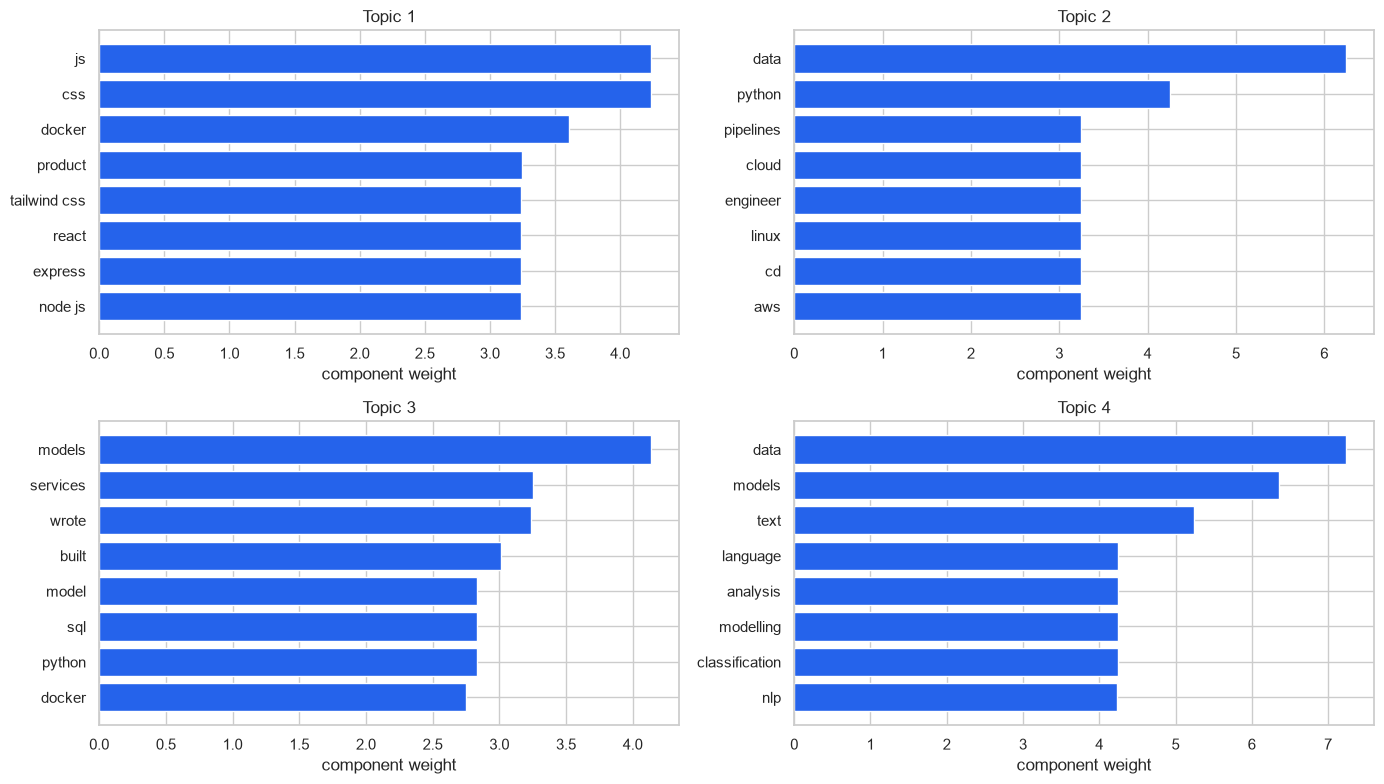

In [6]:
def topic_keyword_frame(model, feature_names, top_n=8):
    rows = []
    for topic_id, component in enumerate(model.components_, start=1):
        top_idx = component.argsort()[::-1][:top_n]
        rows.append({
            "topic": f"Topic {topic_id}",
            "keywords": ", ".join(feature_names[i] for i in top_idx),
            "terms": [feature_names[i] for i in top_idx],
            "weights": [round(float(component[i]), 2) for i in top_idx],
        })
    return pd.DataFrame(rows)

topic_kw = topic_keyword_frame(lda, terms)
display(topic_kw[["topic", "keywords"]])

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (_, row) in zip(axes.flat, topic_kw.iterrows()):
    ax.barh(row.terms[::-1], row.weights[::-1], color="#2563eb")
    ax.set_title(row.topic)
    ax.set_xlabel("component weight")
plt.tight_layout()
plt.show()

## 6. Document-topic distributions

LDA returns a probability distribution over topics for every document. The dominant topic
is the one with the highest probability. These values are model outputs, not manually
assigned labels.

In [7]:
topic_cols = [f"Topic {i}" for i in range(1, N_TOPICS + 1)]
doc_topic_df = pd.DataFrame(doc_topic, columns=topic_cols)
doc_topic_df.insert(0, "document", corpus_df["title"].values)
doc_topic_df.insert(1, "category", corpus_df["category"].values)
doc_topic_df["dominant_topic"] = doc_topic_df[topic_cols].idxmax(axis=1)
doc_topic_df["dominant_weight"] = doc_topic_df[topic_cols].max(axis=1)

display(doc_topic_df.round(3))
print("Dominant topic counts:")
display(doc_topic_df.dominant_topic.value_counts().sort_index().rename("documents").to_frame())

,document,category,Topic 1,Topic 2,Topic 3,Topic 4,dominant_topic,dominant_weight
0,Resume - Data Scientist (Priya S.),resume,0.003,0.003,0.498,0.496,Topic 3,0.498
1,Resume - Machine Learning Engineer (Arjun M.),resume,0.003,0.003,0.991,0.003,Topic 3,0.991
2,Resume - NLP Engineer (Meera I.),resume,0.002,0.002,0.002,0.993,Topic 4,0.993
3,Resume - Python Backend Developer (Rahul V.),resume,0.003,0.003,0.992,0.003,Topic 3,0.992
4,Resume - Full-Stack Developer (Sneha K.),resume,0.400,0.003,0.594,0.003,Topic 3,0.594
5,Resume - DevOps Engineer (Vikram R.),resume,0.003,0.991,0.003,0.003,Topic 2,0.991
6,Resume - Data Analyst (Ananya P.),resume,0.003,0.990,0.003,0.004,Topic 2,0.990
7,Job - Data Scientist,job_description,0.003,0.003,0.003,0.991,Topic 4,0.991
8,Job - NLP Engineer,job_description,0.003,0.003,0.003,0.991,Topic 4,0.991
9,Job - Python Backend Engineer,job_description,0.003,0.991,0.003,0.003,Topic 2,0.991


Dominant topic counts:


,documents
dominant_topic,
Topic 1,3
Topic 2,4
Topic 3,4
Topic 4,4


## 7. Topic visualisation

The heatmap shows the full document-topic matrix. The bar chart summarises which topic
dominates each document type, making it easier to see whether resumes and job descriptions
cluster around different themes.

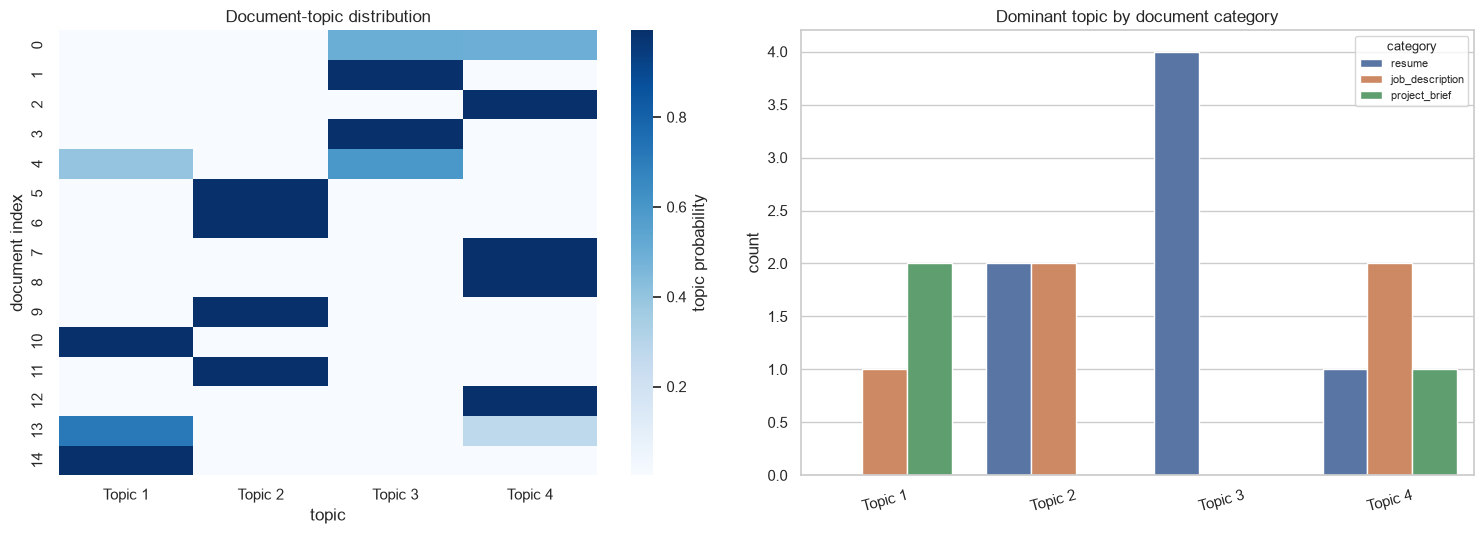

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.heatmap(
    doc_topic,
    cmap="Blues", annot=False, cbar_kws={"label": "topic probability"}, ax=axes[0],
)
axes[0].set_title("Document-topic distribution")
axes[0].set_xlabel("topic")
axes[0].set_ylabel("document index")
axes[0].set_xticklabels(topic_cols, rotation=0)

sns.countplot(
    data=doc_topic_df, x="dominant_topic", hue="category", order=topic_cols, ax=axes[1]
)
axes[1].set_title("Dominant topic by document category")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(title="category", fontsize=8, title_fontsize=9)

plt.tight_layout()
plt.show()

## 8. Results and interpretation

For each topic we print the three documents with the highest assignment probability. This
connects the abstract keyword list back to concrete corpus items.

In [9]:
for topic in topic_cols:
    keywords = topic_kw.loc[topic_kw.topic == topic, "keywords"].iloc[0]
    top_docs = (
        doc_topic_df.nlargest(3, topic)[["document", topic]]
        .round(3)
    )
    print(f"\n{topic}: {keywords}")
    for _, row in top_docs.iterrows():
        print(f"   {row[topic]:.3f}  {row['document']}")

mean_dom = doc_topic_df.dominant_weight.mean()
print(f"\nMean dominant-topic probability: {mean_dom:.3f}")
print(
    "Interpretation: the themes below are induced from word co-occurrence. Because the "
    "corpus is small and intentionally sample-based, treat them as a demonstration of the "
    "method rather than production-grade labels."
)


Topic 1: js, css, docker, product, tailwind css, react, express, node js
   0.991  Project brief - Analytics dashboard platform
   0.990  Job - Full-Stack Developer
   0.716  Project brief - Support ticket triage

Topic 2: data, python, pipelines, cloud, engineer, linux, cd, aws
   0.991  Job - Python Backend Engineer
   0.991  Resume - DevOps Engineer (Vikram R.)
   0.991  Job - DevOps / Cloud Engineer

Topic 3: models, services, wrote, built, model, sql, python, docker
   0.992  Resume - Python Backend Developer (Rahul V.)
   0.991  Resume - Machine Learning Engineer (Arjun M.)
   0.594  Resume - Full-Stack Developer (Sneha K.)

Topic 4: data, models, text, language, analysis, modelling, classification, nlp
   0.993  Resume - NLP Engineer (Meera I.)
   0.991  Job - NLP Engineer
   0.991  Job - Data Scientist

Mean dominant-topic probability: 0.913
Interpretation: the themes below are induced from word co-occurrence. Because the corpus is small and intentionally sample-based, treat t

### Conclusion

LDA successfully discovers recurring themes such as data science/ML, web development,
cloud/DevOps and database work from the unlabelled corpus. `CountVectorizer` supplies a
transparent bag-of-words/bigram representation and the document-topic matrix shows how
strongly each resume or job description belongs to each theme. All numbers, keywords and
charts above are produced by executing this notebook; none are hardcoded. Use
*Kernel → Restart & Run All* to reproduce them.